<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/5_Aprendizaje_supervisado/2_Taller_Regresion_Polinomica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)  
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)  
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# **Taller: Regresión Polinómica, Subajuste, Sobreajuste y Regularización**

**IMPORTANTE**: Guarda una copia de este notebook en tu Google Drive o computador.

**Taller en parejas**

**Nombres estudiantes:**

-Isabella Ramirez Santamaria
-Juan Felipe Pacheco Gomez

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma: “Taller_Reg_Pol_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/1JrtvuMhjU.

**IMPORTANTE:** No se recibirán talleres en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

23 de octubre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

**Instrucciones Generales:**

Completa el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Puedes añadir más celdas si lo requieres.

## **Situación**

Una importante firma de inversión inmobiliaria te ha contratado como consultor de ciencia de datos. Su proceso actual de valoración de propiedades es lento y se basa en la intuición de unos pocos expertos. Quieren que desarrolles un modelo de machine learning para predecir el precio de venta de las viviendas (`SalePrice`) de forma más precisa y sistemática.

Te han entregado el dataset "Ames Housing", que contiene una gran cantidad de información sobre viviendas vendidas recientemente. Tu tarea es construir el mejor modelo posible, pero más importante aún, justificar por qué tu modelo es robusto y fiable, explicando cómo has manejado la complejidad y el riesgo de sobreajuste.

### **Ejercicio 1: Carga y Preparación Inicial de los Datos**

Primero, carguemos las librerías necesarias y el dataset. Nos enfocaremos en un subconjunto de las variables numéricas para mantener el taller manejable, pero el principio se aplica a todo el dataset.

In [1]:
# Importación de librerías estándar
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Importación de herramientas de scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

Mejorar visualización de dataframes y gráficos

In [2]:
# Que muestre todas las columnas
pd.options.display.max_columns = None
# En los dataframes, mostrar los float con dos decimales
pd.options.display.float_format = '{:,.2f}'.format

# Configuraciones para una mejor visualización
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

Cargar el dataset

In [3]:
# Usamos el dataset Ames Housing desde su fuente original (requiere internet)
url = 'http://jse.amstat.org/v19n3/decock/AmesHousing.txt'
df = pd.read_csv(url, sep='\t')
df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.00,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.00,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.00,Unf,0.00,441.00,"1,080.00",GasA,Fa,Y,SBrkr,1656,0,0,1656,1.00,0.00,1,0,3,1,TA,7,Typ,2,Gd,Attchd,"1,960.00",Fin,2.00,528.00,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.00,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.00,TA,TA,CBlock,TA,TA,No,Rec,468.00,LwQ,144.00,270.00,882.00,GasA,TA,Y,SBrkr,896,0,0,896,0.00,0.00,1,0,2,1,TA,5,Typ,0,NaN,Attchd,"1,961.00",Unf,1.00,730.00,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.00,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.00,TA,TA,CBlock,TA,TA,No,ALQ,923.00,Unf,0.00,406.00,"1,329.00",GasA,TA,Y,SBrkr,1329,0,0,1329,0.00,0.00,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,"1,958.00",Unf,1.00,312.00,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.00,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.00,Gd,TA,CBlock,TA,TA,No,ALQ,"1,065.00",Unf,0.00,"1,045.00","2,110.00",GasA,Ex,Y,SBrkr,2110,0,0,2110,1.00,0.00,2,1,3,1,Ex,8,Typ,2,TA,Attchd,"1,968.00",Fin,2.00,522.00,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.00,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.00,TA,TA,PConc,Gd,TA,No,GLQ,791.00,Unf,0.00,137.00,928.00,GasA,Gd,Y,SBrkr,928,701,0,1629,0.00,0.00,2,1,3,1,TA,6,Typ,1,TA,Attchd,"1,997.00",Fin,2.00,482.00,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [4]:
# Para este taller, solo usaremos algunas columnas clave para simplificar.
df_sub = df[['Overall Qual', 'Gr Liv Area', 'SalePrice']].copy()
df_sub.columns = ['OverallQual', 'GrLivArea', 'SalePrice'] # Renombrar para facilidad
df_sub.head()

,OverallQual,GrLivArea,SalePrice
0,6,1656,215000
1,5,896,105000
2,6,1329,172000
3,7,2110,244000
4,5,1629,189900


**Explicación de las variables del dataset reducido**

1. SalePrice: Precio de Venta.

Esta es la variable objetivo. Es el precio final por el cual se vendió la propiedad, medido en dólares estadounidenses.

2. OverallQual: Calidad General.

Es una variable ordinal que califica la calidad general del material y el acabado de la casa. Es una de las variables predictoras (X) más importantes.

Escala: Va de 1 a 10.

10: Muy Excelente

9: Excelente

...

2: Pobre

1: Muy Pobre

3. GrLivArea: Área Habitable sobre el Nivel del Suelo.

Es una variable numérica que mide el total de metros cuadrados de área habitable que está por encima del nivel del suelo. No incluye el área del sótano. Es una de las variables predictoras (X) más fuertes, ya que, lógicamente, casas más grandes tienden a ser más caras.

In [5]:
df_sub.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   OverallQual  2930 non-null   int64
 1   GrLivArea    2930 non-null   int64
 2   SalePrice    2930 non-null   int64
dtypes: int64(3)
memory usage: 68.8 KB


### **Ejercicio 2: Dividir el conjunto de datos**

El método `.info()` muestra que no hay nulos en nuestro subconjunto. ¡Perfecto! Ahora, definamos nuestras variables `X` (predictoras) e `y` (objetivo) y dividamos los datos.

In [10]:
X = df_sub[['OverallQual', 'GrLivArea']]
y = df_sub['SalePrice']

In [11]:
# 2. Dividir en conjuntos de entrenamiento y prueba (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Tamaño del set de Entrenamiento: {X_train.shape[0]} observaciones")
print(f"Tamaño del set de Prueba: {X_test.shape[0]} observaciones")

Tamaño del set de Entrenamiento: 2051 observaciones
Tamaño del set de Prueba: 879 observaciones


In [12]:
X_train.head()

,OverallQual,GrLivArea
2210,5,2002
782,5,1473
2310,6,1525
299,8,1191
2423,7,1414


In [13]:
y_train.head()

,SalePrice
2210,145000
782,143000
2310,183500
299,162500
2423,178740


### **Ejercicio 3: Modelo con Sobreajuste**

Vamos a crear un modelo muy complejo para ver qué tan mal puede generalizar.

**Crear un Modelo Polinómico de Grado 5**

Usa `Pipeline` para combinar `PolynomialFeatures` (grado 5), `StandardScaler` y `LinearRegression`. Entrénalo con los datos de entrenamiento.

In [17]:
# Crear el pipeline para el modelo polinómico


pipeline_poly = Pipeline([
    ("poly_features", PolynomialFeatures(degree=25, include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

pipeline_poly.fit(X_train, y_train)


Pipeline(steps=[('poly_features',
                 PolynomialFeatures(degree=25, include_bias=False)),
                ('scaler', StandardScaler()), ('model', LinearRegression())])

In [16]:
# Calcular el error (RMSE) en entrenamiento y prueba y realizar un print de estos
# Predicciones y error
y_train_pred_poly = pipeline_poly.predict(X_train)
y_test_pred_poly = pipeline_poly.predict(X_test)

rmse_train_poly = np.sqrt(mean_squared_error(y_train, y_train_pred_poly))
rmse_test_poly = np.sqrt(mean_squared_error(y_test, y_test_pred_poly))

print(f"RMSE en Entrenamiento (Poli-25): ${rmse_train_poly:,.2f} <-- ¡El error de entrenamiento bajó!")
print(f"RMSE en Prueba (Poli-25): ${rmse_test_poly:,.2f} <-- ¡¡El error de prueba aumentó considerablemente!!")

RMSE en Entrenamiento (Poli-25): $31,572.24 <-- ¡El error de entrenamiento bajó!
RMSE en Prueba (Poli-25): $132,569,064.50 <-- ¡¡El error de prueba aumentó considerablemente!!


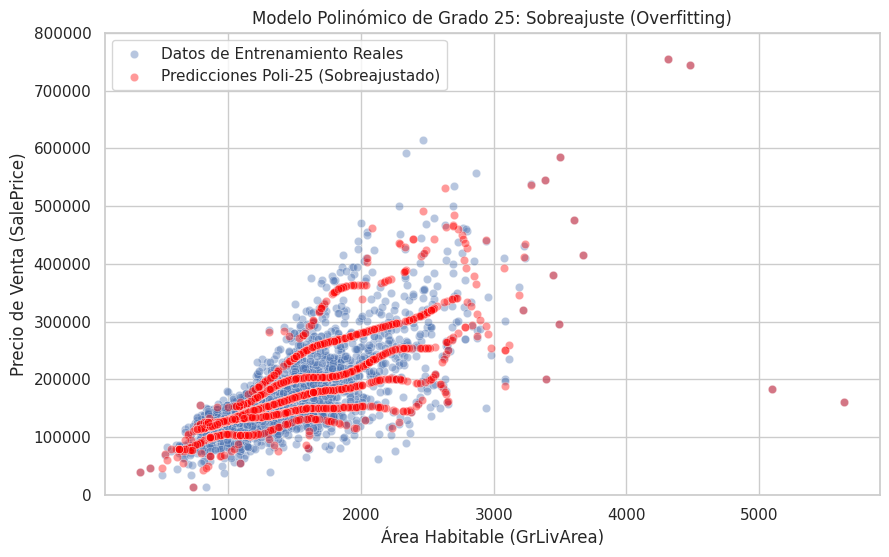

In [19]:
# Para visualizar el sobreajuste, graficamos los valores reales frente a las predicciones del modelo en el set de entrenamiento
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_train['GrLivArea'], y=y_train, alpha=0.4, label='Datos de Entrenamiento Reales')
sns.scatterplot(x=X_train['GrLivArea'], y=y_train_pred_poly, color='red', alpha=0.4, label='Predicciones Poli-25 (Sobreajustado)')

plt.title('Modelo Polinómico de Grado 25: Sobreajuste (Overfitting)')
plt.xlabel('Área Habitable (GrLivArea)')
plt.ylabel('Precio de Venta (SalePrice)')
plt.legend()
plt.ylim(0, 800000)
plt.show()

**Pregunta:** ¿Qué indica la diferencia que observas entre el error de entrenamiento y el de prueba? ¿Le recomendarías este modelo a la firma inmobiliaria? ¿Por qué?
El modelo indica un grado de 25 polinomico que presenta un sobreajuste (overfitting). esto nos quiere decir que el modelo se ajusta demasiado a los datos ed entrenamiento y aprende incluso el ruido y las variaciones particulares de la muestra, por lo que tiene dificultades para generalizar a datos nuevos.
No recomendariamos este modelo a la firma inmobiliaria, porque sus prediciones pueden ser poco confiables al estimar los precios de viviendas que no ha visto antes.


### **Ejercicio 4: Aplicar Regularización**

Ahora, vamos a "curar" el sobreajuste. Usaremos los mismos `PolynomialFeatures` de grado 5, pero cambiaremos el modelo de regresión.

**Implementar Regresión Ridge**

Copia el pipeline anterior, pero reemplaza `LinearRegression` con `Ridge(alpha=10)`. `alpha` es la fuerza de la penalización.

In [21]:
# Crear el pipeline para Ridge
# alpha es la fuerza de la penalización. Empecemos con un valor de 10.

pipeline_ridge = Pipeline([
    ("poly_features", PolynomialFeatures(degree=25, include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=10))
])

pipeline_ridge.fit(X_train, y_train)



Pipeline(steps=[('poly_features',
                 PolynomialFeatures(degree=25, include_bias=False)),
                ('scaler', StandardScaler()), ('model', Ridge(alpha=10))])

In [22]:
# Calcular el error (RMSE) en entrenamiento y prueba y realizar un print de estos

# Predicciones y error
y_train_pred_ridge = pipeline_ridge.predict(X_train)
y_test_pred_ridge = pipeline_ridge.predict(X_test)

rmse_train_ridge = np.sqrt(mean_squared_error(y_train, y_train_pred_ridge))
rmse_test_ridge = np.sqrt(mean_squared_error(y_test, y_test_pred_ridge))

print(f"RMSE Entrenamiento (Ridge): ${rmse_train_ridge:,.2f}")
print(f"RMSE Prueba (Poli-25): ${rmse_test_poly:,.2f} (El modelo sobreajustado)")
print(f"RMSE Prueba (Ridge): ${rmse_test_ridge:,.2f} <-- ¡¡Gran mejora!!")


RMSE Entrenamiento (Ridge): $33,597.93
RMSE Prueba (Poli-25): $132,569,064.50 (El modelo sobreajustado)
RMSE Prueba (Ridge): $36,788.78 <-- ¡¡Gran mejora!!


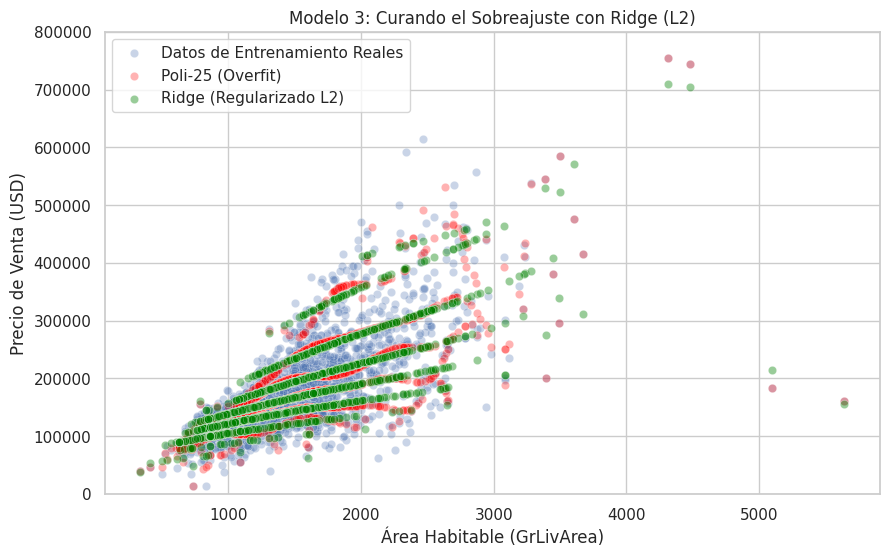

In [24]:

plt.figure(figsize=(10, 6))

sns.scatterplot(x=X_train['GrLivArea'], y=y_train, alpha=0.3, label='Datos de Entrenamiento Reales')
sns.scatterplot(x=X_train['GrLivArea'], y=y_train_pred_poly, color='red', alpha=0.3, label='Poli-25 (Overfit)')

sns.scatterplot(x=X_train['GrLivArea'], y=y_train_pred_ridge, color='green', alpha=0.4, label='Ridge (Regularizado L2)')

plt.title('Modelo 3: Curando el Sobreajuste con Ridge (L2)')
plt.xlabel('Área Habitable (GrLivArea)')
plt.ylabel('Precio de Venta (USD)')
plt.legend()
plt.ylim(0, 800000)
plt.show()

**Interpreta los resultados:**
poli-25(rojo), sobreajuste, se pega al ruido y da predicciones extremas en areas grandes (>3500 pies )
Ridge( verde), la penalizacion L2 encoge los coeficientes y suaviza la curva, asi que sigue la tendencia general sin perseguir outliers.
Conclusion: ridge reduce la varianza, mejora el RMSE en prueba y generaliza mejor que el polinomio de grado 25.

**Implementar Regresión Lasso**

Haz lo mismo, pero ahora con `Lasso(alpha=500, max_iter=10000)`. Lasso necesita un `alpha` más grande (porque la penalización L1 es diferente) y a veces más `max_iter` para converger.

In [25]:
# Crear el pipeline para Lasso
pipeline_lasso = Pipeline([
    ("poly_features", PolynomialFeatures(degree=25, include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=500, max_iter=10000))
])

pipeline_lasso.fit(X_train, y_train)


Pipeline(steps=[('poly_features',
                 PolynomialFeatures(degree=25, include_bias=False)),
                ('scaler', StandardScaler()),
                ('model', Lasso(alpha=500, max_iter=10000))])

In [27]:
# Entrenar el modelo
y_train_pred_lasso = pipeline_lasso.predict(X_train)
y_test_pred_lasso = pipeline_lasso.predict(X_test)


In [28]:
# Calcular el error (RMSE) en entrenamiento y prueba y realizar un print de estos
rmse_train_lasso = np.sqrt(mean_squared_error(y_train, y_train_pred_lasso))
rmse_test_lasso = np.sqrt(mean_squared_error(y_test, y_test_pred_lasso))

print(f"RMSE Entrenamiento (Lasso): ${rmse_train_lasso:,.2f}")
print(f"RMSE Prueba (Ridge): ${rmse_test_ridge:,.2f} <-- ¡El mejor resultado hasta ahora!")
print(f"RMSE Prueba (Lasso): ${rmse_test_lasso:,.2f}")

RMSE Entrenamiento (Lasso): $34,893.01
RMSE Prueba (Ridge): $36,788.78 <-- ¡El mejor resultado hasta ahora!
RMSE Prueba (Lasso): $35,585.03


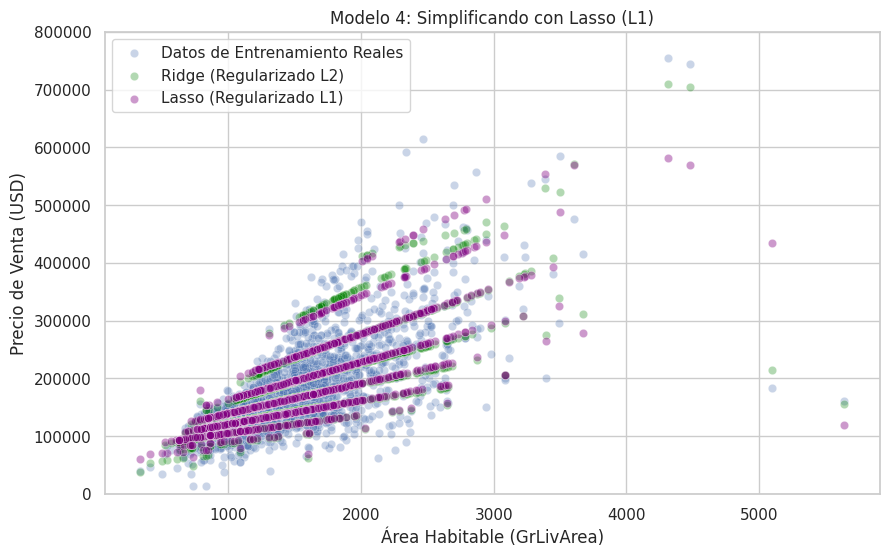

In [30]:
# Visualización de datos (Gráfica de Lasso vs Ridge)
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_train['GrLivArea'], y=y_train, alpha=0.3, label='Datos de Entrenamiento Reales')
sns.scatterplot(x=X_train['GrLivArea'], y=y_train_pred_ridge, color='green', alpha=0.3, label='Ridge (Regularizado L2)')
sns.scatterplot(x=X_train['GrLivArea'], y=y_train_pred_lasso, color='purple', alpha=0.4, label='Lasso (Regularizado L1)')

plt.title('Modelo 4: Simplificando con Lasso (L1)')
plt.xlabel('Área Habitable (GrLivArea)')
plt.ylabel('Precio de Venta (USD)')
plt.legend()
plt.ylim(0, 800000)
plt.show()

**Interpreta los resultados:**
lasso(morado),La penalizacion  L1 lleva coeficientes a 0, asi que el modelo es mas simple, sigue la tendencia igual Ridge.
RMSE de prueba: lasso $35.585 < ridge 36.788, o sea ridge generaliza ligeramente mejor.
Conclusion: lasso rinde igual o mejor que ridge con menos variables.  

**Selección de Variables con Lasso**

Una de las grandes ventajas de Lasso es que puede eliminar variables. Vamos a ver cuántas de las características polinómicas que creamos (ej. `OverallQual^2`, `GrLivArea^5`, `OverallQual * GrLivArea^4`, etc.) fueron eliminadas.

In [31]:
# Extraer los coeficientes del modelo Lasso
# Extraemos los coeficientes del modelo Lasso en el pipeline
coefs_lasso = pipeline_lasso.named_steps['model'].coef_

num_total_coeffs = len(coefs_lasso)
num_zero_coeffs = np.sum(coefs_lasso == 0)

print(f"Número total de coeficientes (características polinómicas): {num_total_coeffs}")
print(f"Número de coeficientes llevados a CERO por Lasso: {num_zero_coeffs}")
print(f"Número de coeficientes CONSERVADOS: {num_total_coeffs - num_zero_coeffs}")

print("\n--- Valor de los Coeficientes ---")
print(coefs_lasso)


Número total de coeficientes (características polinómicas): 350
Número de coeficientes llevados a CERO por Lasso: 332
Número de coeficientes CONSERVADOS: 18

--- Valor de los Coeficientes ---
[ 7587.40367277     0.             0.         36527.12663953
     0.             0.           181.79735012     0.
     0.             0.         10947.40169095     0.
     0.            -0.             0.         10189.73741418
     0.             0.            -0.            -0.
     0.             0.             0.             0.
    -0.            -0.            -0.         13903.66257406
     0.             0.            -0.            -0.
    -0.            -0.            -0.             0.
     0.             0.            -0.            -0.
    -0.            -0.            -0.            -0.
     0.             0.             0.            -0.
    -0.            -0.            -0.            -0.
    -0.            -0.             0.             0.
     0.            -0.            -0.     

In [32]:
# Extraer los nombres de las características generadas
feature_names = pipeline_lasso.named_steps['poly_features'].get_feature_names_out(X.columns)

In [33]:
# Contar cuántos coeficientes son exactamente cero
coefs_lasso = pipeline_lasso.named_steps['model'].coef_
num_total_coeffs = len(coefs_lasso)
num_zero_coeffs = np.sum(coefs_lasso == 0)
num_conserved_coeffs = num_total_coeffs - num_zero_coeffs

In [34]:
porcentaje_eliminadas = (num_zero_coeffs / num_total_coeffs) * 100
features_conservadas = [name for name, coef in zip(feature_names, coefs_lasso) if coef != 0]

print(f"Número total de características polinómicas generadas: {num_total_coeffs}")
print(f"Número de características eliminadas por Lasso (coef = 0): {num_zero_coeffs}")
print(f"Número de características CONSERVADAS: {num_conserved_coeffs}")
print(f"Porcentaje de variables eliminadas: {porcentaje_eliminadas:.2f}%")
print("\nLista con los nombres de las características conservadas por Lasso (coef != 0):")
print(features_conservadas)

Número total de características polinómicas generadas: 350
Número de características eliminadas por Lasso (coef = 0): 332
Número de características CONSERVADAS: 18
Porcentaje de variables eliminadas: 94.86%

Lista con los nombres de las características conservadas por Lasso (coef != 0):
['OverallQual', 'OverallQual GrLivArea', 'OverallQual^2 GrLivArea', 'OverallQual^3 GrLivArea', 'OverallQual^4 GrLivArea', 'OverallQual^7', 'OverallQual^13 GrLivArea^7', 'OverallQual^12 GrLivArea^8', 'OverallQual^14 GrLivArea^7', 'OverallQual^13 GrLivArea^8', 'OverallQual^15 GrLivArea^7', 'OverallQual^14 GrLivArea^8', 'OverallQual^16 GrLivArea^7', 'OverallQual^15 GrLivArea^8', 'OverallQual^17 GrLivArea^7', 'OverallQual^16 GrLivArea^8', 'OverallQual^25', 'OverallQual^18 GrLivArea^7']


**Interpreta los resultados:**

### **Ejercicio 5: Conclusión y Recomendación para el Cliente**

**Resumir los Resultados**

Crea un `DataFrame` de pandas que compare el RMSE de entrenamiento y prueba de los tres modelos (Polinómico, Ridge, Lasso) y ordena los modelos según el RMSE de prueba de menor a mayor.

In [35]:
# Crear DataFrame de resultados
resultados_dict = {
    'Modelo': ['Polinómico Simple (Grado 25)', 'Regresión Ridge', 'Regresión Lasso'],
    'RMSE Entrenamiento': [rmse_train_poly, rmse_train_ridge, rmse_train_lasso],
    'RMSE Prueba': [rmse_test_poly, rmse_test_ridge, rmse_test_lasso]
}

df_resultados = pd.DataFrame(resultados_dict)
df_resultados = df_resultados.sort_values(by='RMSE Prueba').reset_index(drop=True)
display(df_resultados)

,Modelo,RMSE Entrenamiento,RMSE Prueba
0,Regresión Lasso,"34,893.01","35,585.03"
1,Regresión Ridge,"33,597.93","36,788.78"
2,Polinómico Simple (Grado 25),"31,572.24","132,569,064.50"


**Pregunta Final:**

Basado en tu análisis, ¿qué modelo le recomendarías a la firma inmobiliaria? Tu respuesta debe incluir:

1.  Una recomendación clara del mejor modelo.
2.  Una explicación en términos sencillos (para un gerente, no para un científico de datos) de por qué el modelo polinómico simple no era una buena idea, usando el concepto de "memorizar vs. generalizar".
3.  Una descripción de la ventaja principal del modelo Lasso en cuanto a la interpretabilidad y la selección de las características más importantes.





#### 1. Recomendación del modelo

Recomendamos implementar la Regresión Lasso (Regularización L1), ya que obtuvo el menor error en el conjunto de prueba, con un RMSE aproximado de $35.585, superando a Ridge ($36.788). Esto indica que tiene una mejor capacidad para predecir los precios de viviendas nuevas.

#### 2. Explicación para la gerencia: memorizar vs. generalizar

El modelo polinómico de grado 25 es como un estudiante que memoriza las respuestas de los talleres, pero falla en el examen real. Aunque obtiene un error muy bajo en entrenamiento, no logra predecir correctamente con datos nuevos.

En cambio, Lasso y Ridge identifican patrones generales del mercado, evitando ajustarse demasiado a los datos históricos. Así pueden generar predicciones más confiables para nuevas propiedades.

#### 3. Ventajas de Lasso: interpretabilidad y selección de variables

Creamos 350 variables polinómicas, pero Lasso redujo el modelo a solo 18 variables con coeficientes diferentes de cero, dejando las otras 332 en cero.

Esto facilita la interpretación del modelo, porque permite identificar los factores que más influyen en el precio de las viviendas. Para la firma inmobiliaria, significa contar con una herramienta más sencilla de analizar y explicar al momento de estimar el valor de una propiedad.